# Fourier transform of the 4 measurements: GloVe top 5, LCA likely top 3 (10%), surprisal, BERT mean cosine

The 25 texts' curves are read from the saved CSVs (nothing is measured again):
- **GloVe top 5, LCA likely top 3 (10%), surprisal per word**: the Qwen7B run, `Qwen7B/results/run/words` and `tokens`
- **BERT mean cosine**: `src/Results_CSV/cosine`

For each measurement (one cell each):
1. **all 25 spectra on one graph**: thin line per text, thick line = factual / creative average
2. **a table**: per text, the strongest wave (period in words), fast share (share of word-to-word jitter), total power
3. **each text's own graph** (`SHOW_EACH_TEXT = True`): the curve with its smooth trend, and its spectrum

The last cell compares the 4 measurements: average fast share of factual vs creative texts.

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

REPO = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "src" / "tools").exists())
QWEN_DIR = REPO / "src" / "note_books" / "Qwen7B"
for folder in (REPO, QWEN_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

from src.tools.fourier_transform import fast_share, fourier_transform, plot_fourier, plot_spectra, spectrum_table
from analysis.signals import curves_of, dataset_names, load_tables, signal_by_key
from config.qwen_config import MODEL_NAME

SHOW_EACH_TEXT = True                         # False: only the overlay graph and the table per measurement
COSINE_DIR = REPO / "src" / "Results_CSV" / "cosine"
COSINE_TAG = MODEL_NAME.replace("/", "_")     # file names: Qwen_Qwen2.5-7B-Instruct__<text>.csv

QWEN_MEASUREMENTS = {
    "GloVe top 5": "glove_top5",
    "LCA likely top 3 (10%)": "lca_likely_top3_10pct",
    "Surprisal": "surprisal_per_word",
}
BERT_NAME = "BERT mean cosine"

In [2]:
# Every text's curve of every measurement: {measurement: {text name: curve}}
names = list(dataset_names())                                # the 25 texts of Qwen7B/texts
qwen_words, qwen_tokens = load_tables(names, MODEL_NAME)      # Qwen7B/results/run/words + tokens

measurements = {}
for measurement, key in QWEN_MEASUREMENTS.items():
    curves = curves_of(signal_by_key(key), names, qwen_words, qwen_tokens)
    measurements[measurement] = dict(zip(names, curves))

cosine_curves = {}
for name in names:
    table = pd.read_csv(COSINE_DIR / f"{COSINE_TAG}__{name}.csv", keep_default_na=False, na_values=[""])
    values = pd.to_numeric(table["mean_cos"], errors="coerce")
    cosine_curves[name] = values.dropna().to_numpy()
measurements[BERT_NAME] = cosine_curves

for measurement, curves in measurements.items():
    lengths = [len(c) for c in curves.values()]
    print(f"{measurement}: {len(curves)} texts, {min(lengths)}-{max(lengths)} points each")

GloVe top 5: 25 texts, 128-259 points each
LCA likely top 3 (10%): 25 texts, 128-259 points each
Surprisal: 25 texts, 128-259 points each
BERT mean cosine: 25 texts, 215-402 points each


In [3]:
def fourier_measurement(measurement, show_each=None):
    """One measurement: all spectra on one graph, the table, and (show_each) every text's own graph."""
    curves = measurements[measurement]
    show_each = SHOW_EACH_TEXT if show_each is None else show_each
    display(Markdown(f"## {measurement} ({len(curves)} texts)"))
    plot_spectra(curves, title=f"{measurement}: every text's spectrum")
    with pd.option_context("display.max_rows", 100, "display.width", 200):
        display(spectrum_table(curves))
    if show_each:
        for name, curve in curves.items():
            plot_fourier(curve, title=f"{name}  ({measurement})")

## GloVe top 5 (25 texts)

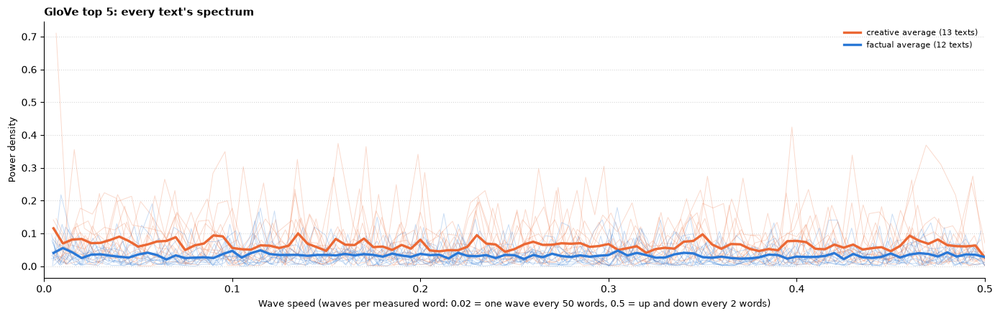

,text,kind,points,strongest wave (waves over text),strongest wave period (words),strongest wave power share,fast share,total power
0,creative_gut_alice,creative,156,62,2.5,0.067,0.495,0.04059
1,creative_gut_grimm,creative,183,31,5.9,0.040,0.458,0.02517
2,creative_gut_oz,creative,129,45,2.9,0.067,0.488,0.02680
3,creative_gut_sherlock,creative,172,41,4.2,0.045,0.516,0.02279
4,creative_hp1,creative,187,32,5.8,0.061,0.420,0.03218
5,creative_hp2,creative,195,26,7.5,0.037,0.408,0.03240
6,creative_hp3,creative,173,35,4.9,0.056,0.419,0.02932
7,creative_hp4,creative,170,18,9.4,0.059,0.392,0.03004
8,creative_hp5,creative,140,52,2.7,0.059,0.540,0.03256
9,creative_hp6,creative,180,83,2.2,0.045,0.559,0.03224


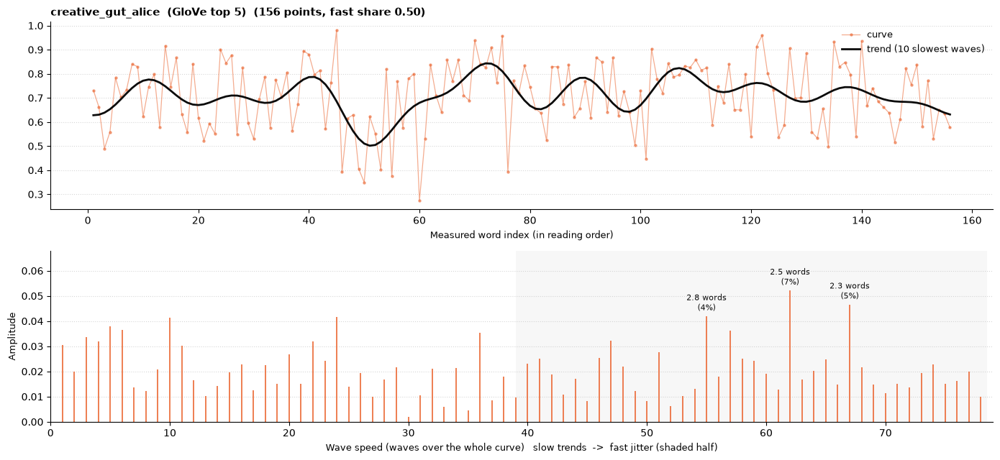

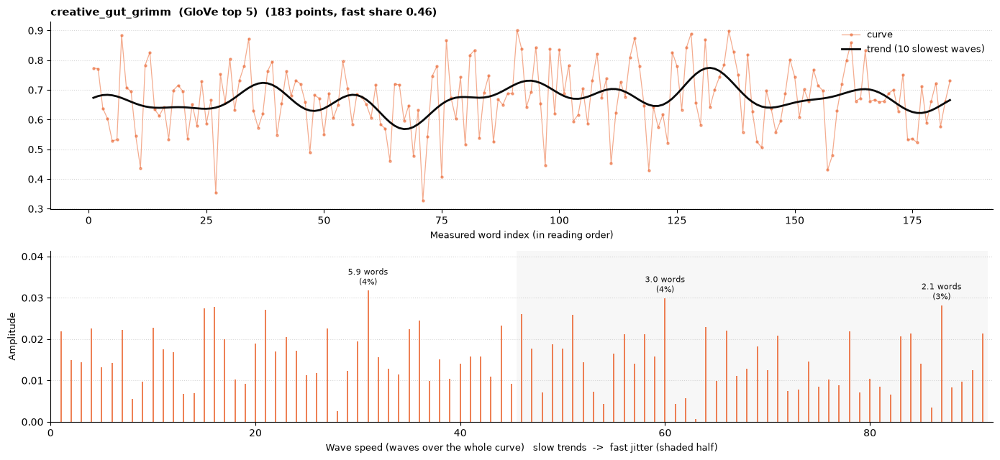

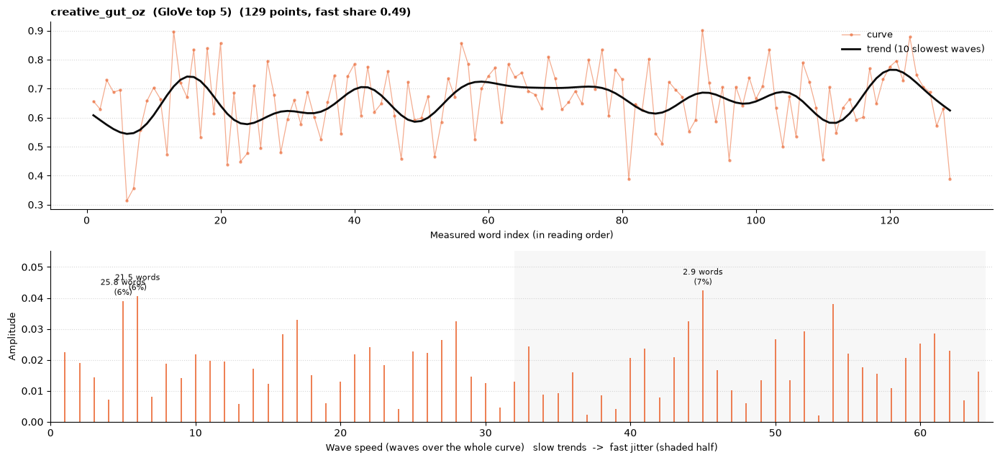

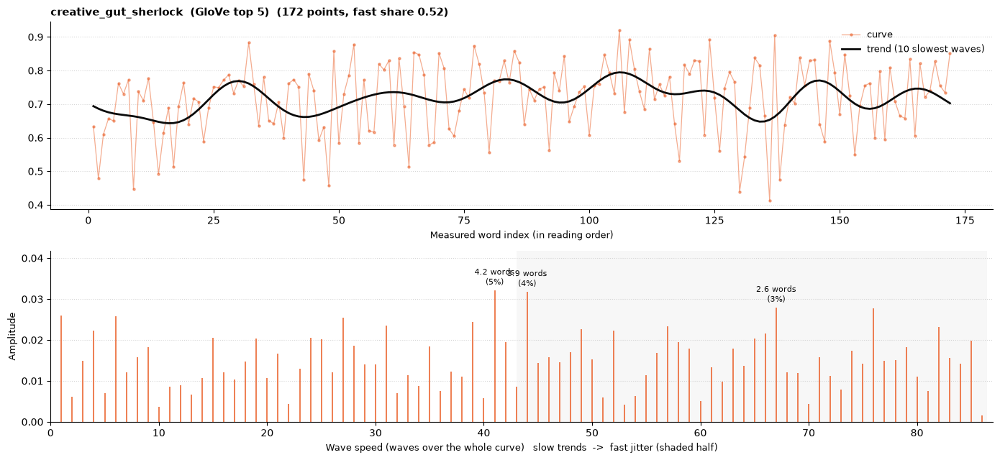

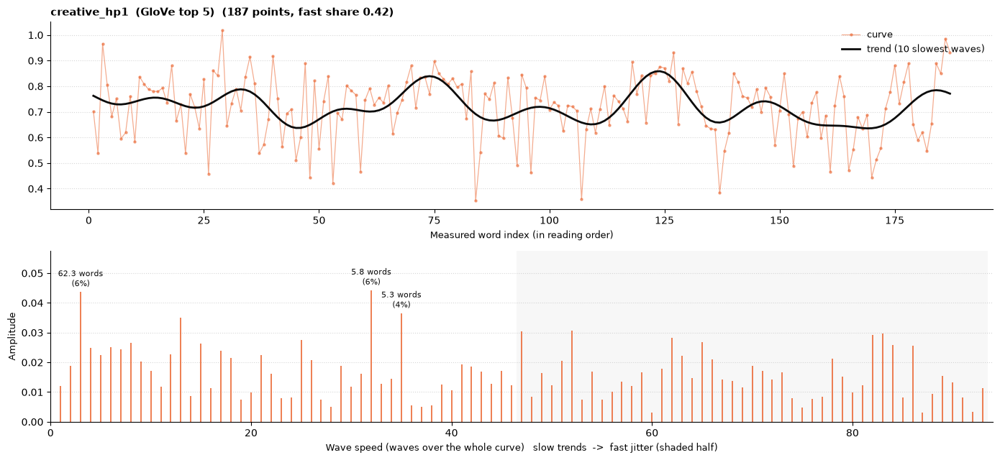

...

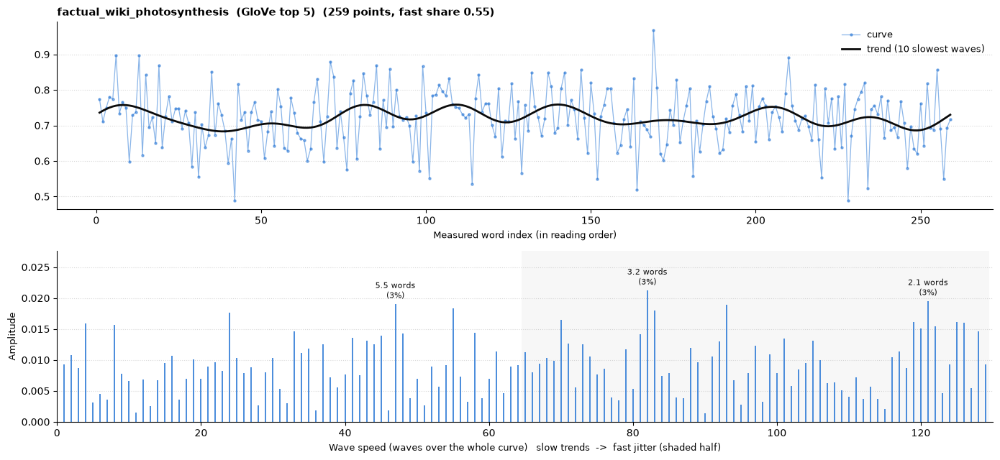

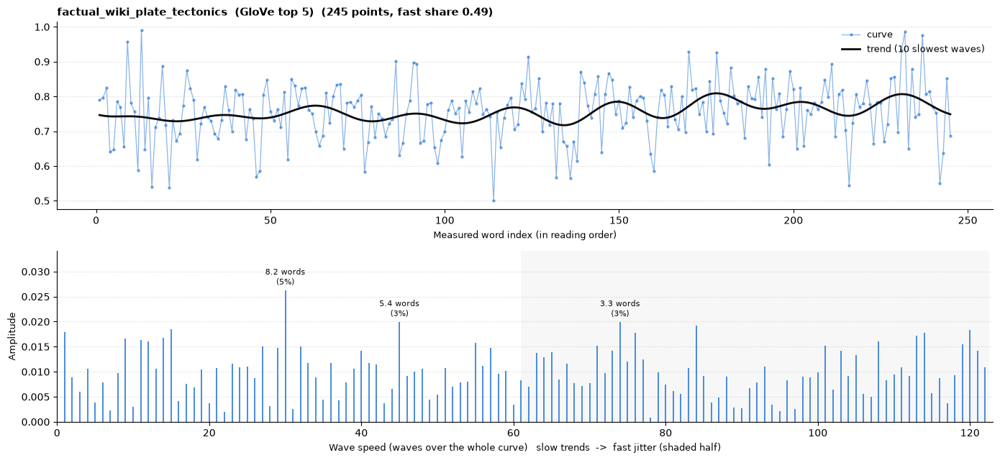

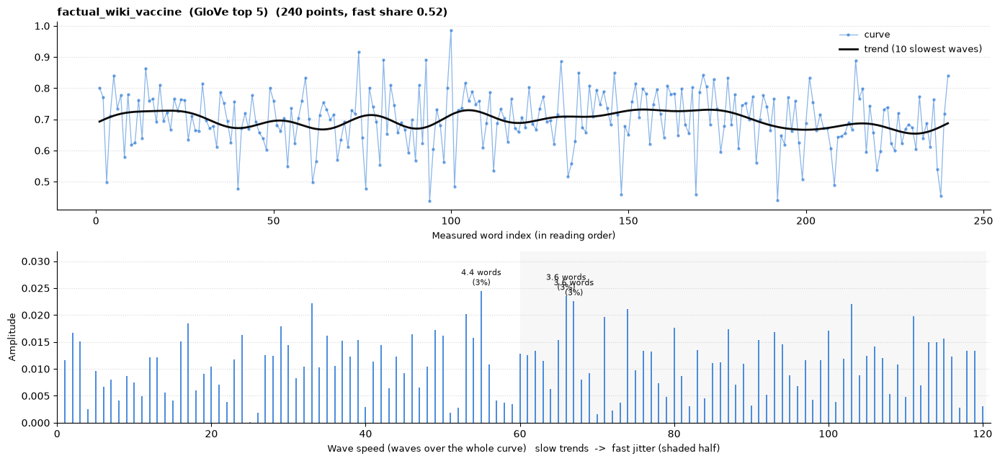

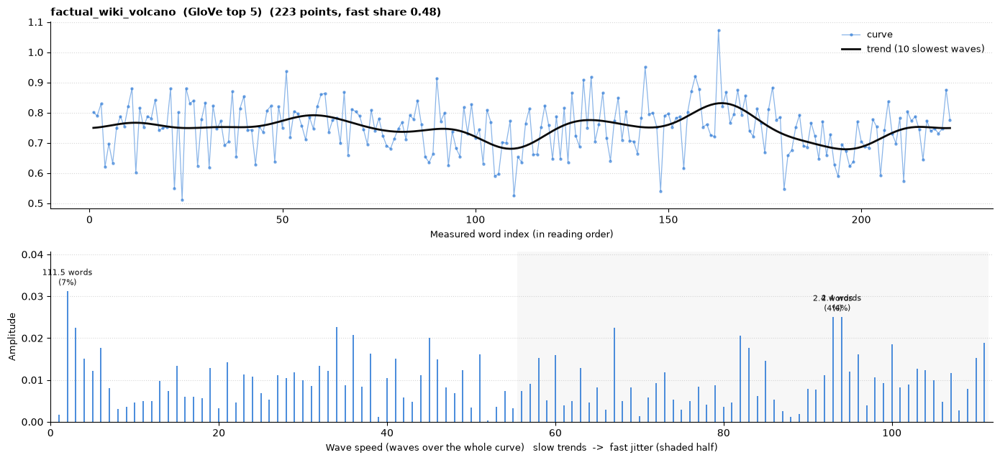

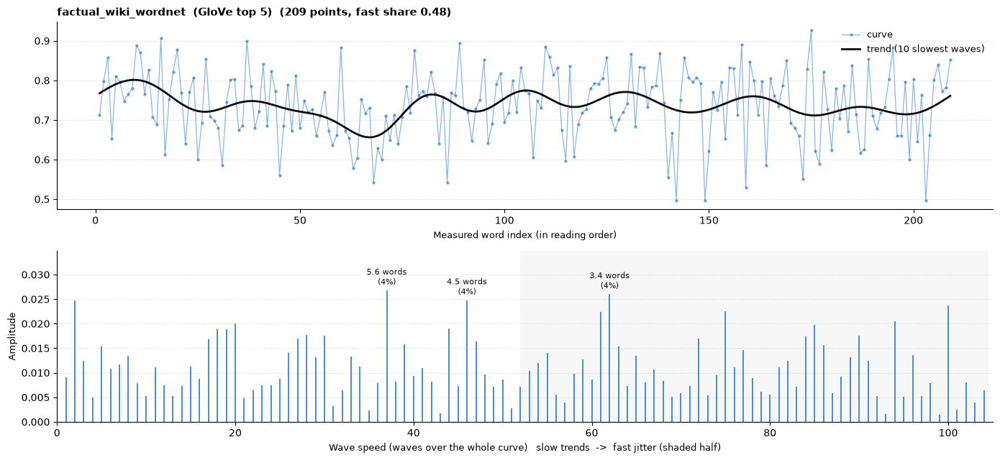

In [4]:
fourier_measurement("GloVe top 5")

## LCA likely top 3 (10%) (25 texts)

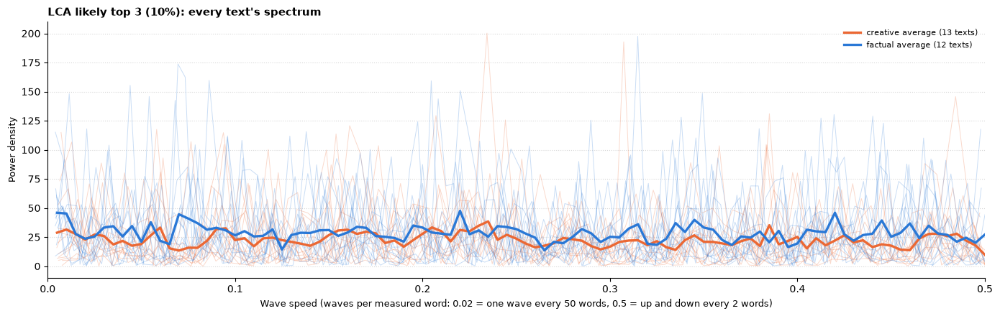

,text,kind,points,strongest wave (waves over text),strongest wave period (words),strongest wave power share,fast share,total power
0,creative_gut_alice,creative,156,24,6.5,0.074,0.438,9.90286
1,creative_gut_grimm,creative,183,11,16.6,0.044,0.453,9.96112
2,creative_gut_oz,creative,129,27,4.8,0.060,0.517,8.59492
3,creative_gut_sherlock,creative,172,42,4.1,0.051,0.491,14.26707
4,creative_hp1,creative,187,72,2.6,0.055,0.514,12.84612
5,creative_hp2,creative,195,29,6.7,0.042,0.368,12.31979
6,creative_hp3,creative,173,67,2.6,0.039,0.448,9.67637
7,creative_hp4,creative,170,13,13.1,0.060,0.409,10.44073
8,creative_hp5,creative,140,29,4.8,0.085,0.345,10.83694
9,creative_hp6,creative,180,29,6.2,0.057,0.484,11.80062


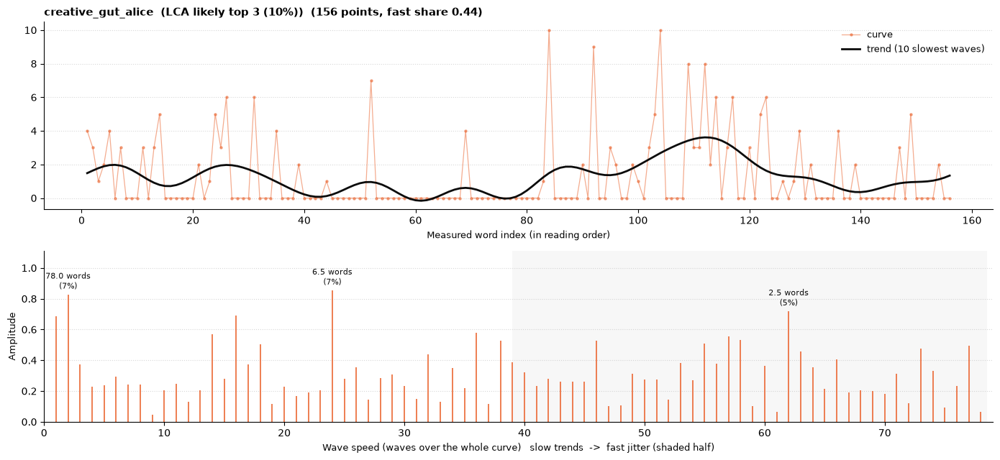

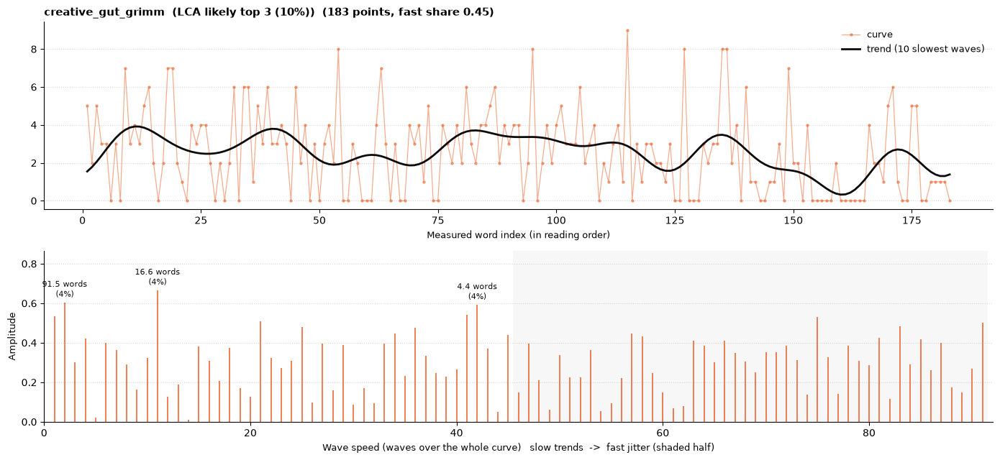

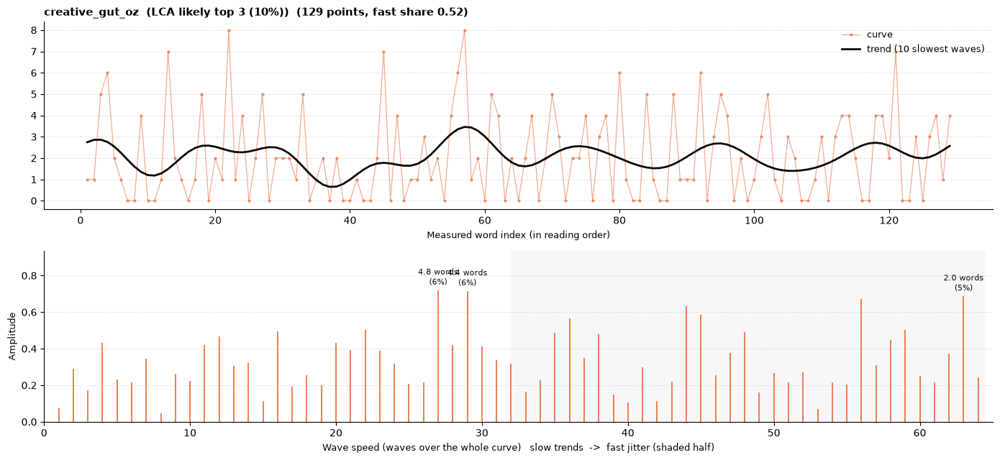

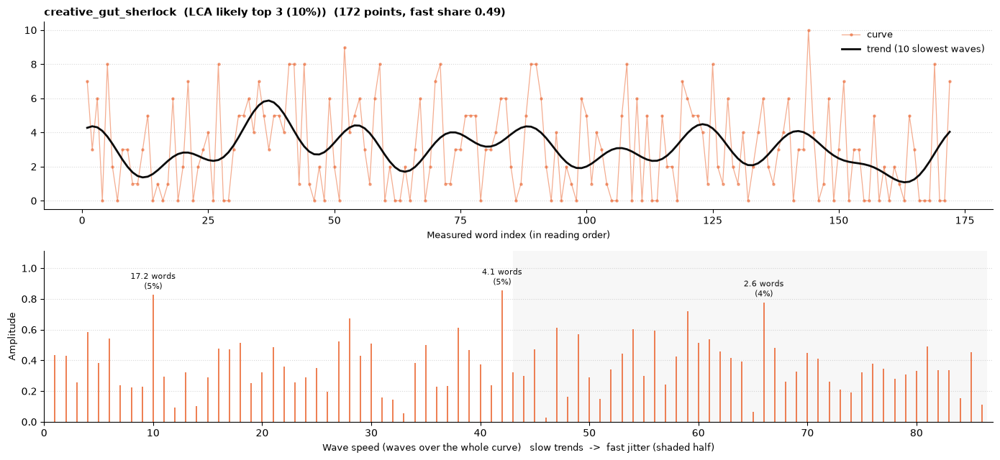

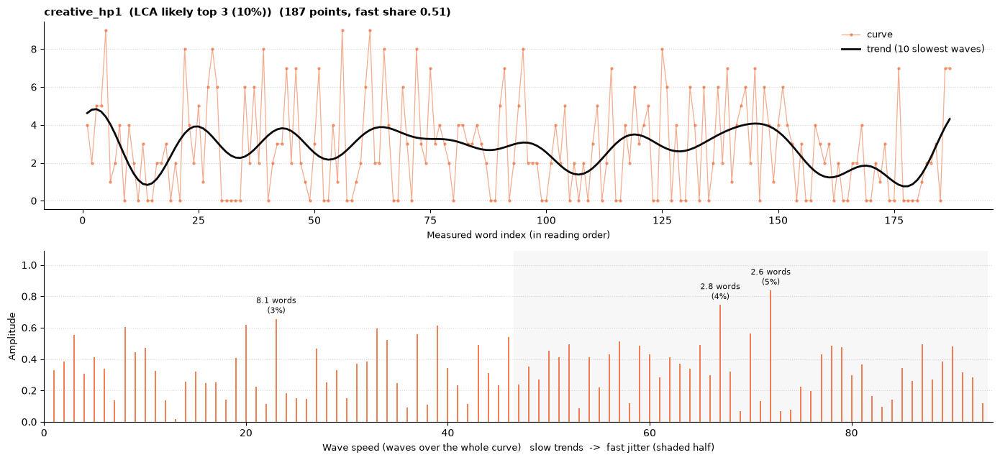

...

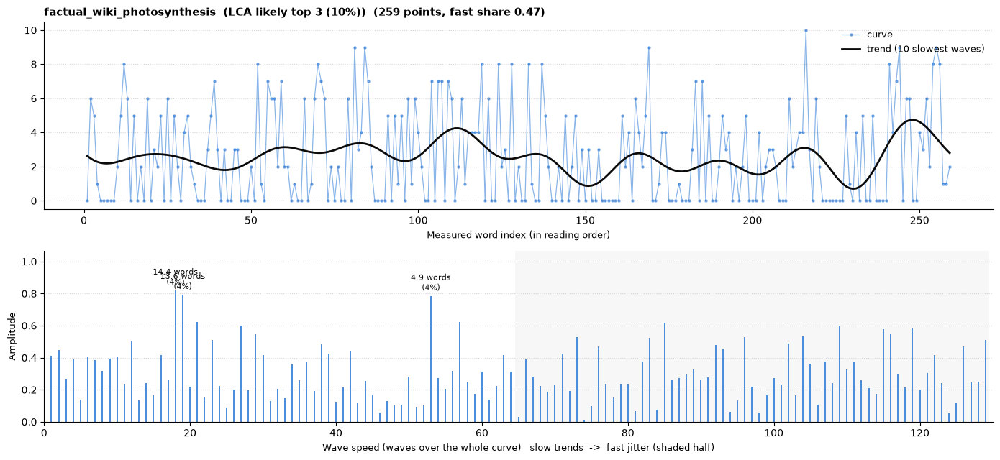

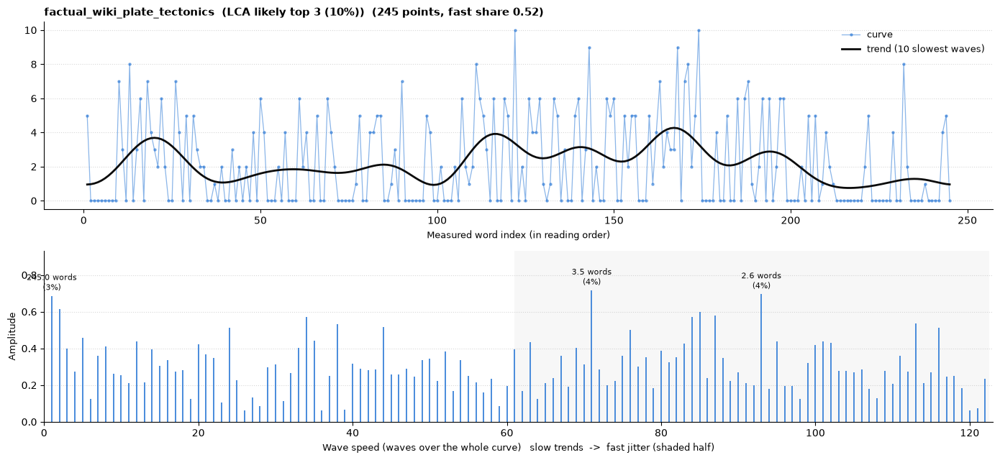

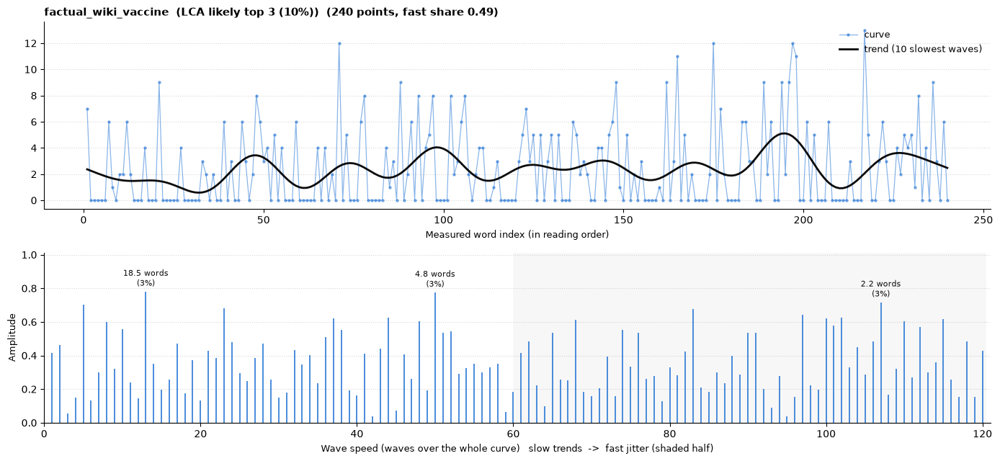

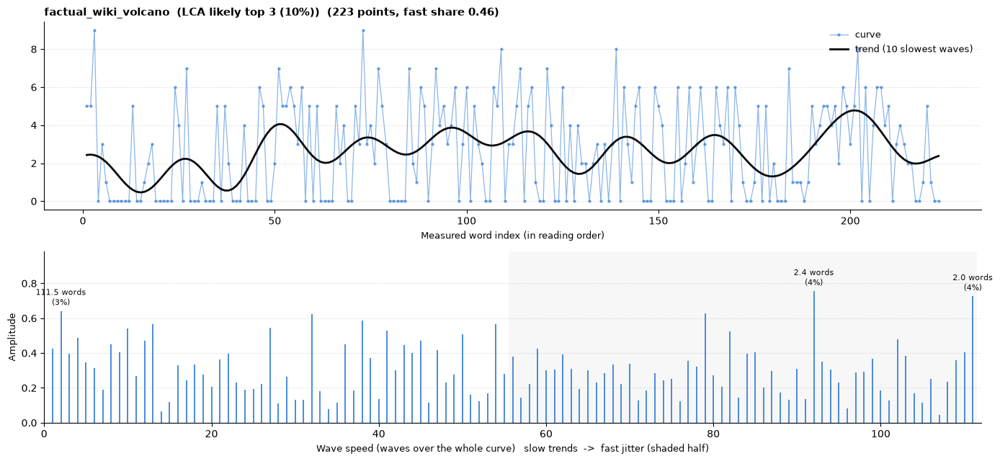

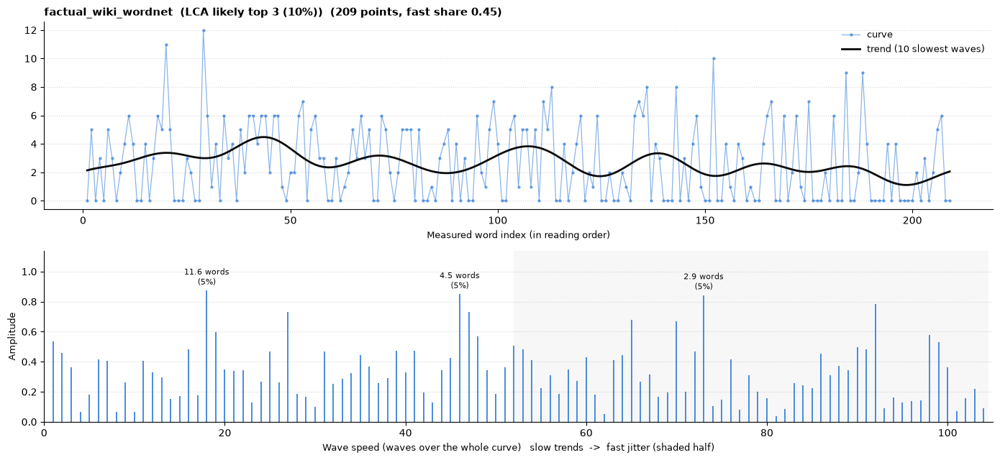

In [5]:
fourier_measurement("LCA likely top 3 (10%)")

## Surprisal (25 texts)

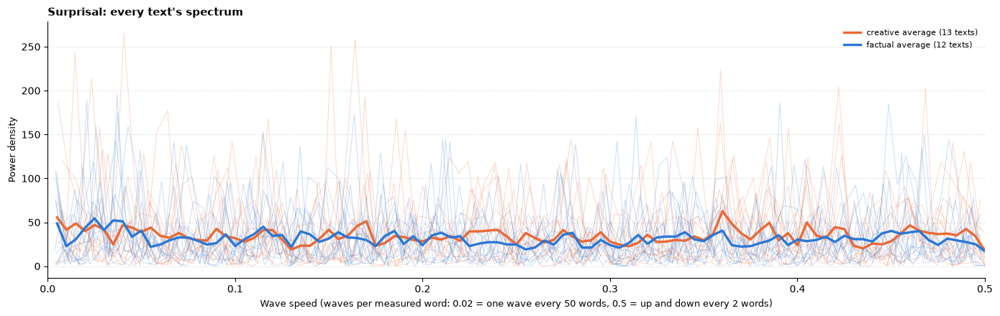

,text,kind,points,strongest wave (waves over text),strongest wave period (words),strongest wave power share,fast share,total power
0,creative_gut_alice,creative,156,1,156.0,0.067,0.479,6.16071
1,creative_gut_grimm,creative,183,1,183.0,0.065,0.369,15.70838
2,creative_gut_oz,creative,129,1,129.0,0.064,0.356,14.61210
3,creative_gut_sherlock,creative,172,7,24.6,0.069,0.437,22.40598
4,creative_hp1,creative,187,6,31.2,0.048,0.451,14.25046
5,creative_hp2,creative,195,70,2.8,0.062,0.553,18.64290
6,creative_hp3,creative,173,73,2.4,0.072,0.516,16.44923
7,creative_hp4,creative,170,20,8.5,0.052,0.569,18.91586
8,creative_hp5,creative,140,10,14.0,0.058,0.573,16.87756
9,creative_hp6,creative,180,76,2.4,0.041,0.561,21.82048


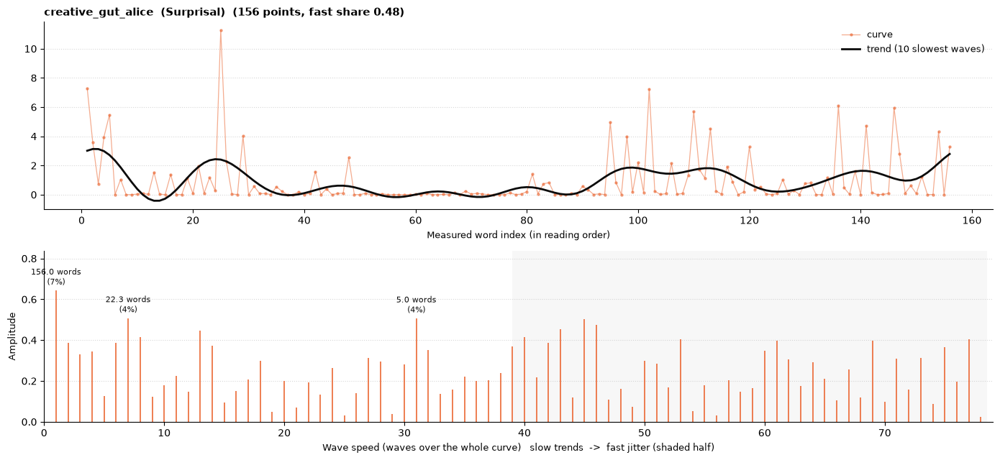

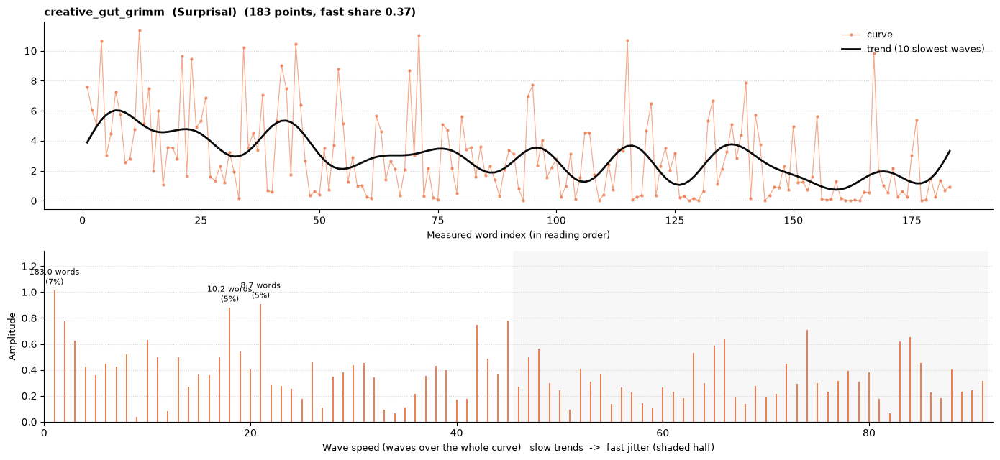

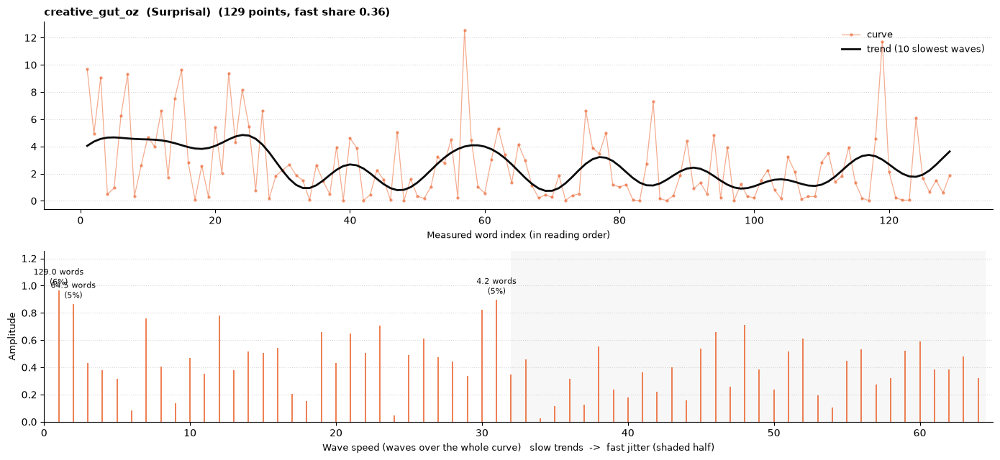

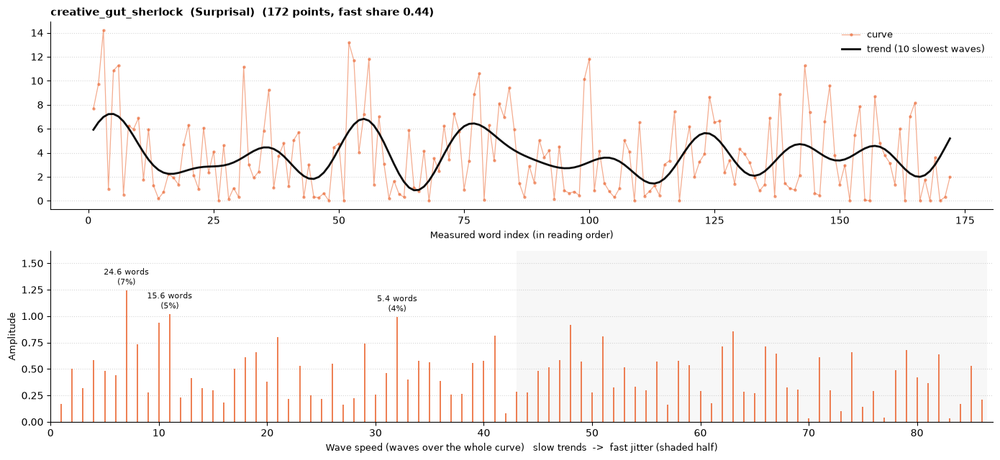

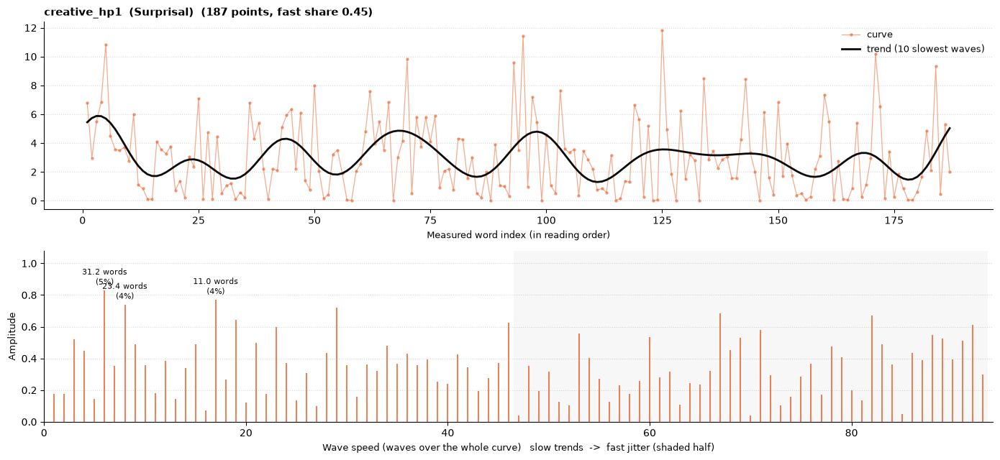

...

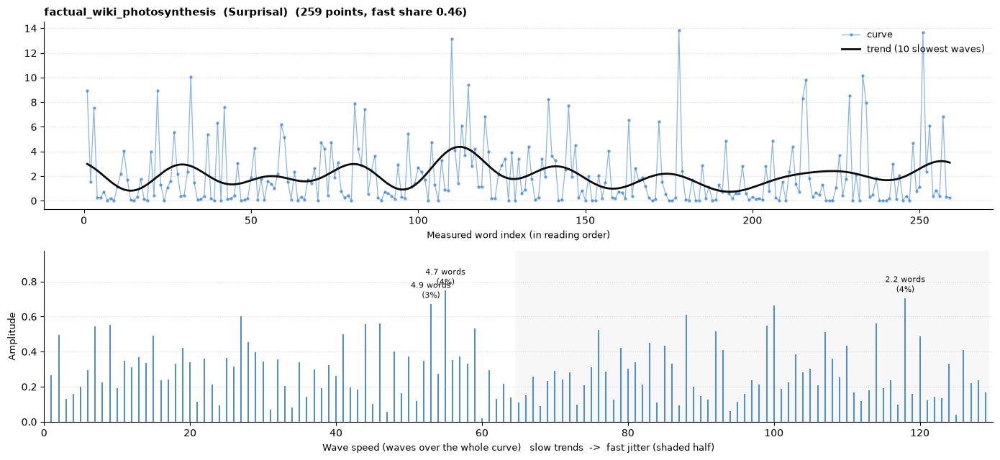

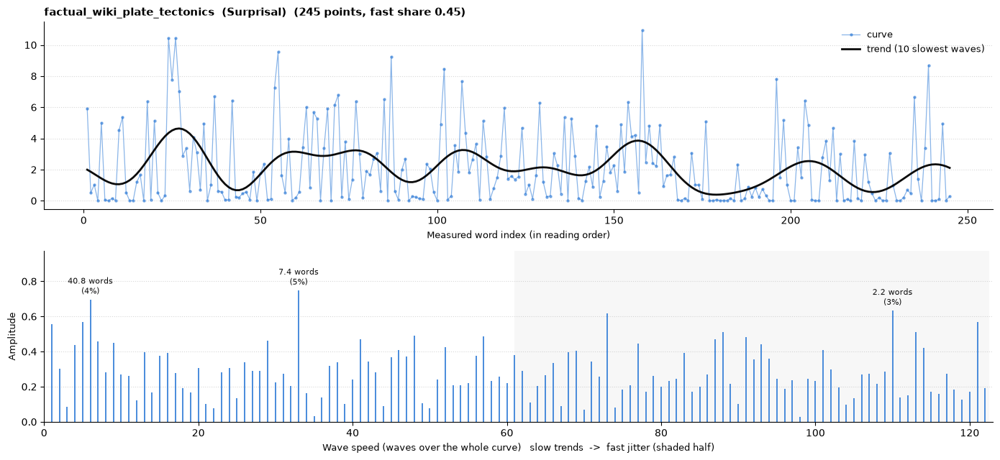

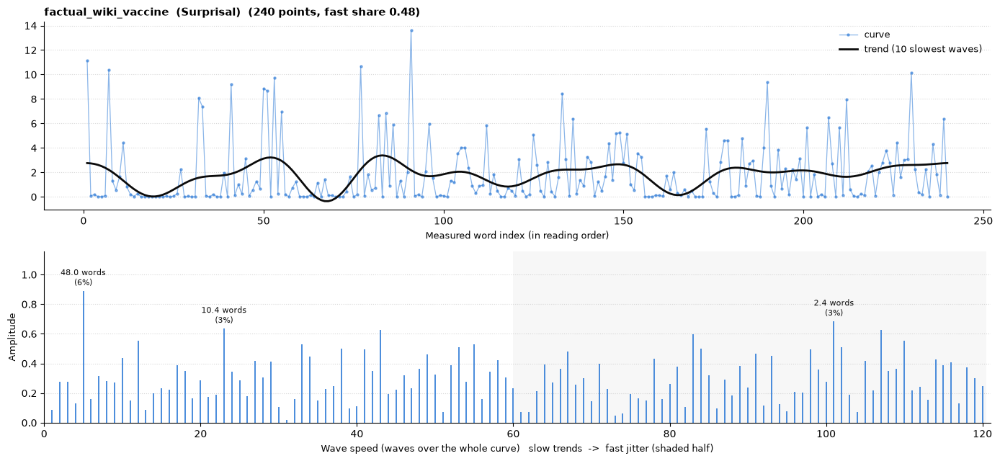

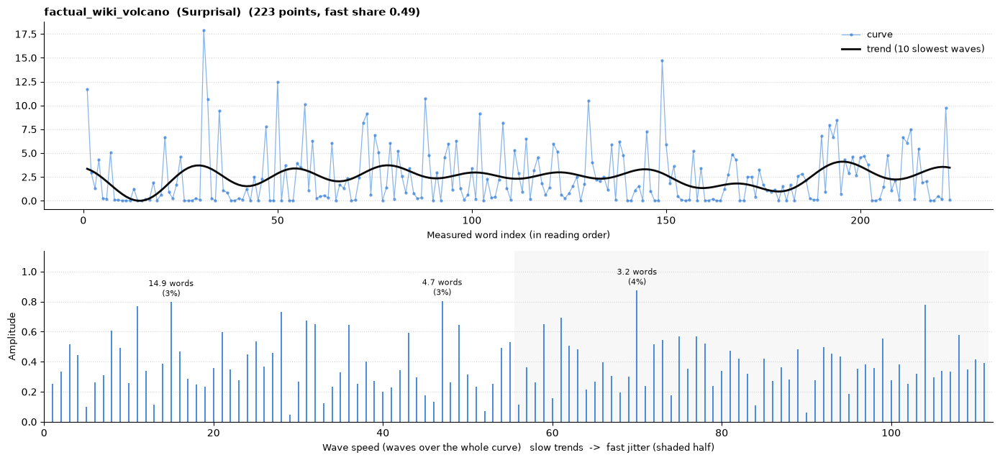

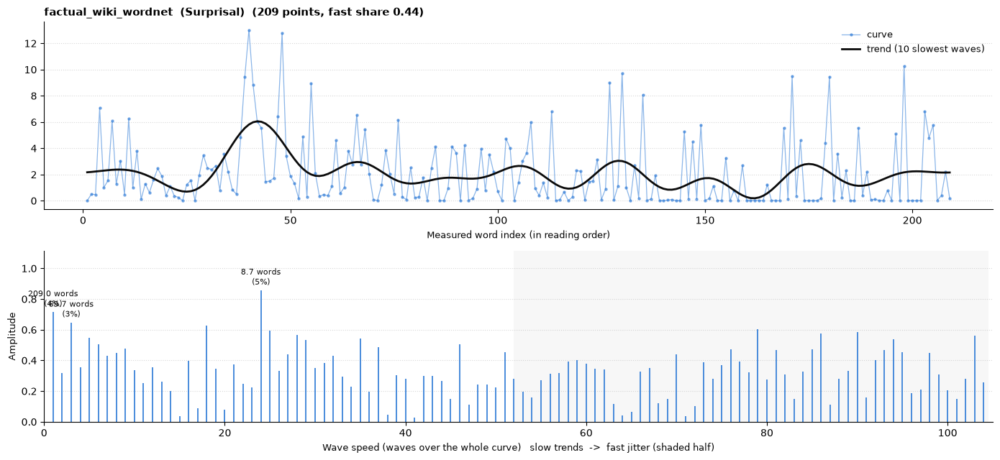

In [6]:
fourier_measurement("Surprisal")

## BERT mean cosine (25 texts)

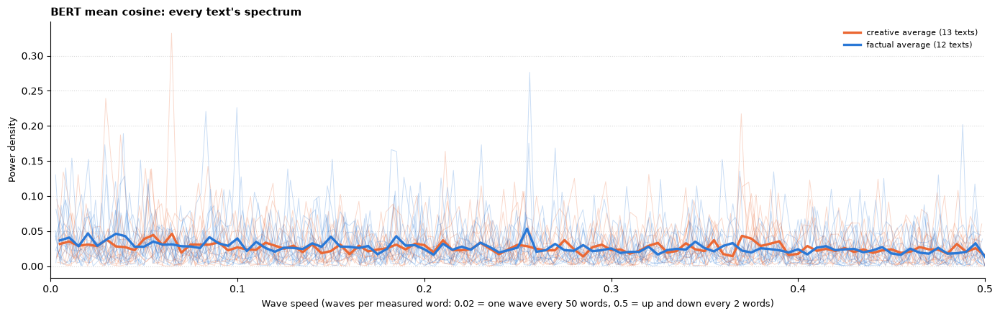

,text,kind,points,strongest wave (waves over text),strongest wave period (words),strongest wave power share,fast share,total power
0,creative_gut_alice,creative,225,57,3.9,0.040,0.493,0.01177
1,creative_gut_grimm,creative,239,67,3.6,0.046,0.506,0.01131
2,creative_gut_oz,creative,243,13,18.7,0.054,0.528,0.01044
3,creative_gut_sherlock,creative,245,38,6.4,0.035,0.458,0.01205
4,creative_hp1,creative,271,8,33.9,0.067,0.401,0.01322
5,creative_hp2,creative,316,28,11.3,0.027,0.438,0.01258
6,creative_hp3,creative,301,73,4.1,0.027,0.448,0.01338
7,creative_hp4,creative,294,11,26.7,0.043,0.395,0.01464
8,creative_hp5,creative,278,18,15.4,0.084,0.433,0.01428
9,creative_hp6,creative,273,23,11.9,0.034,0.488,0.01555


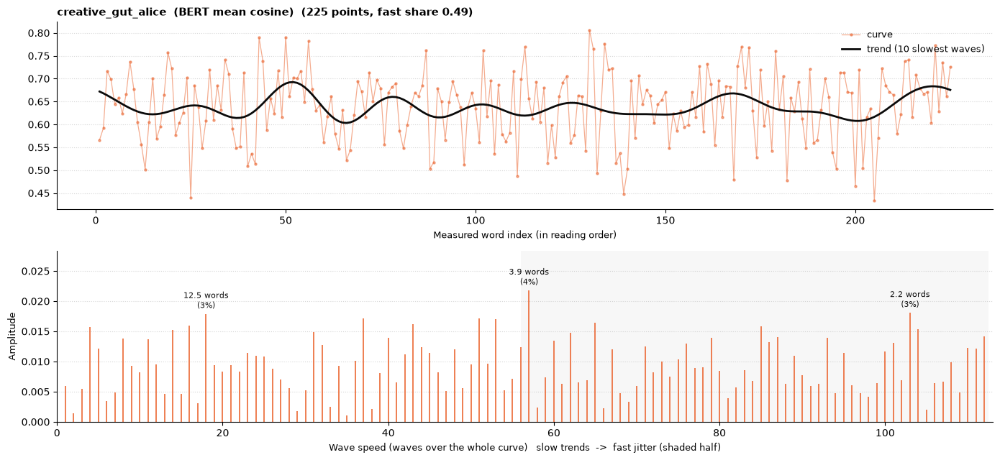

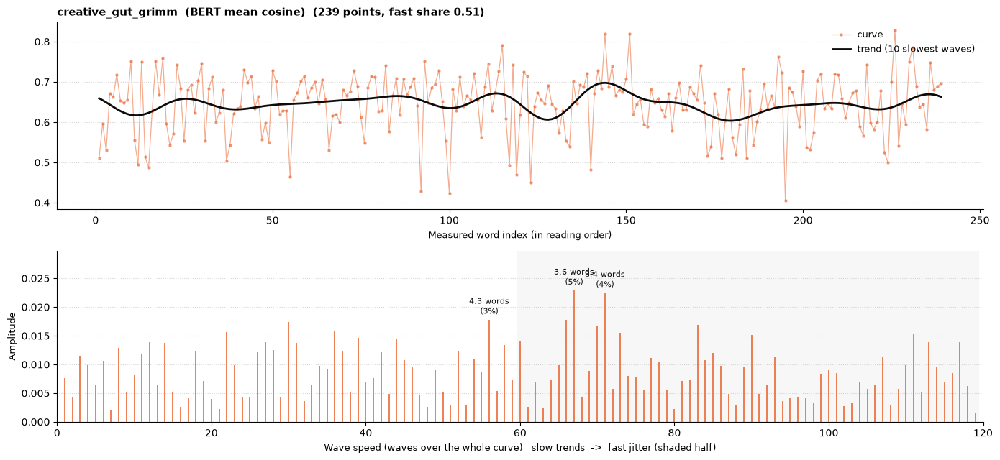

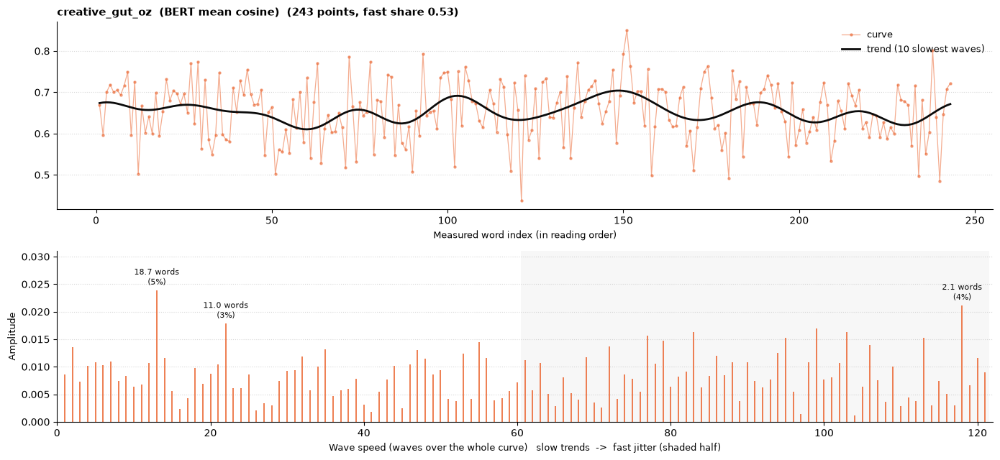

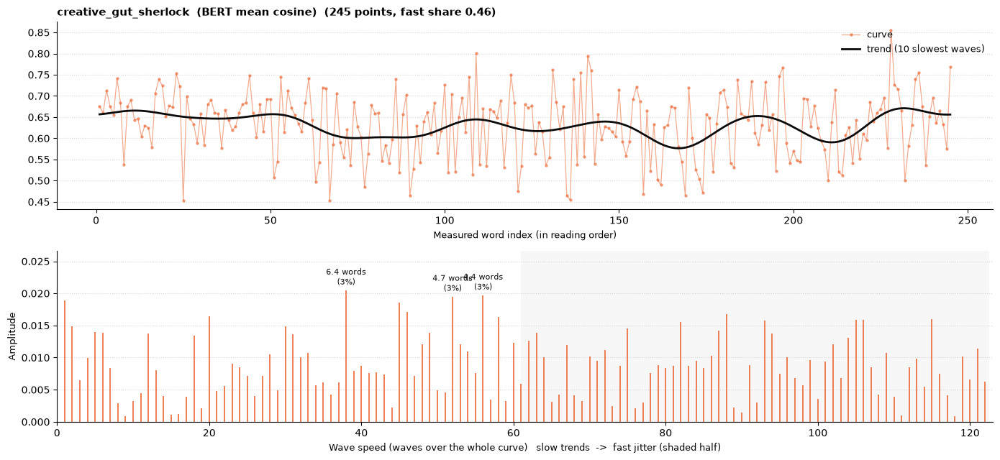

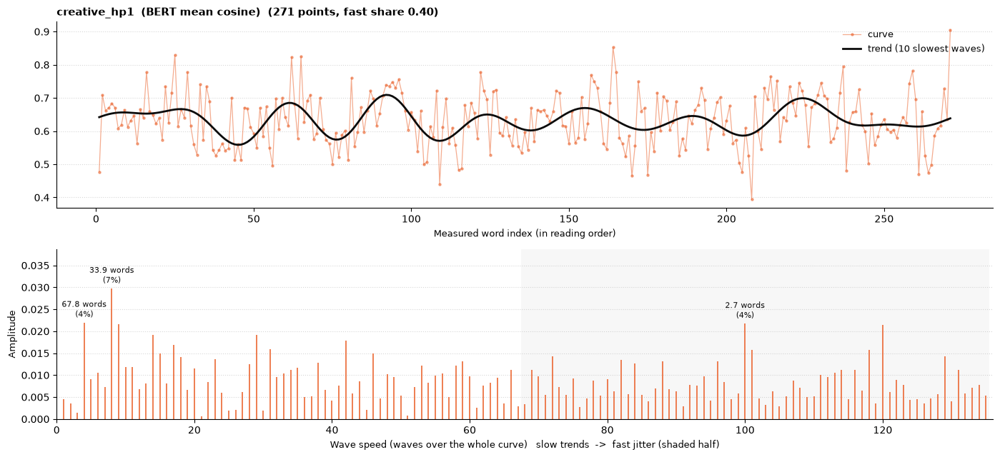

...

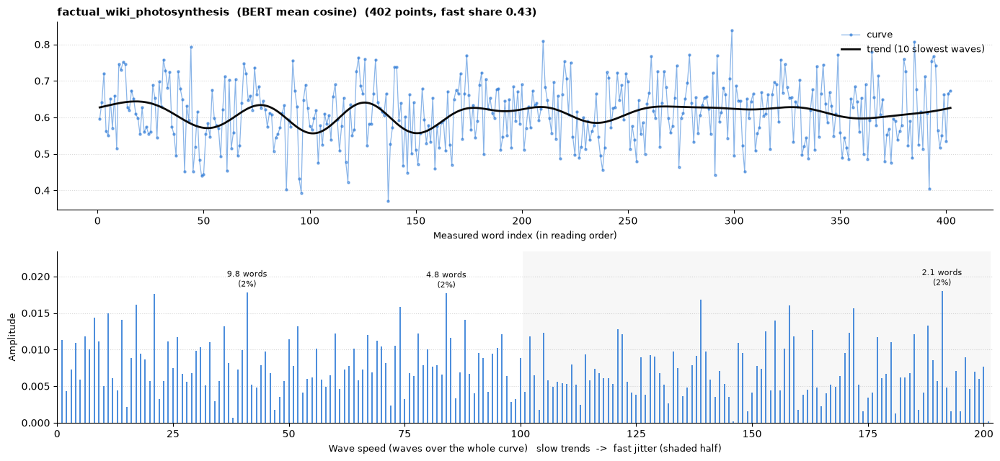

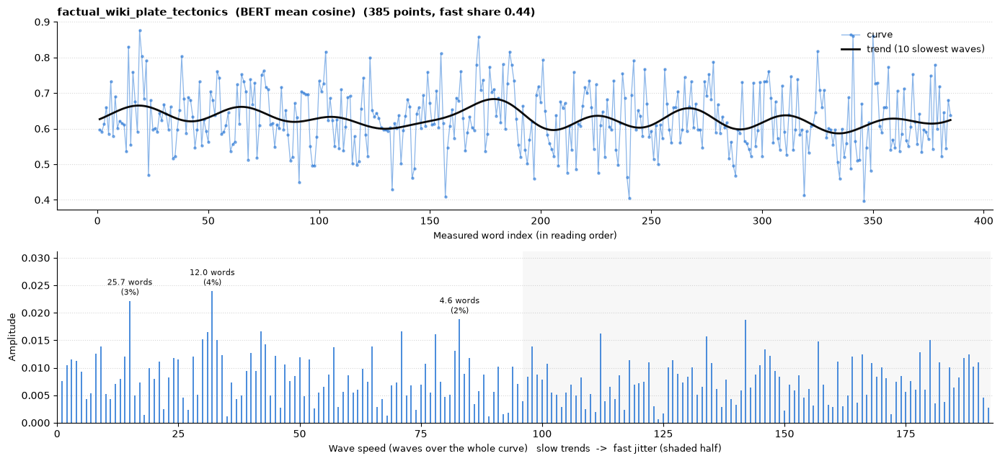

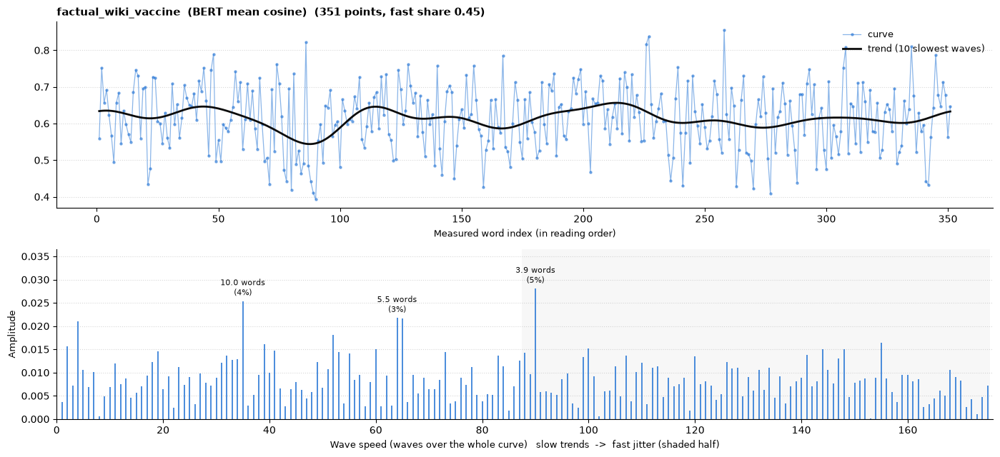

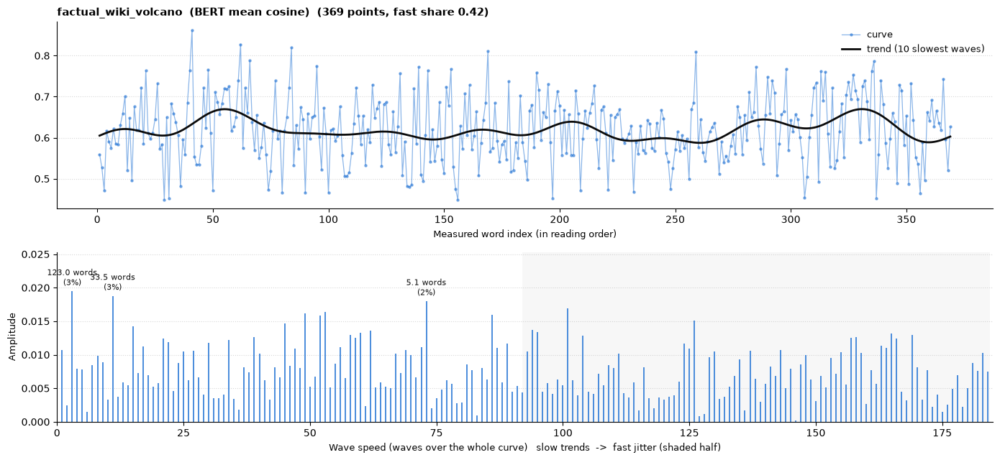

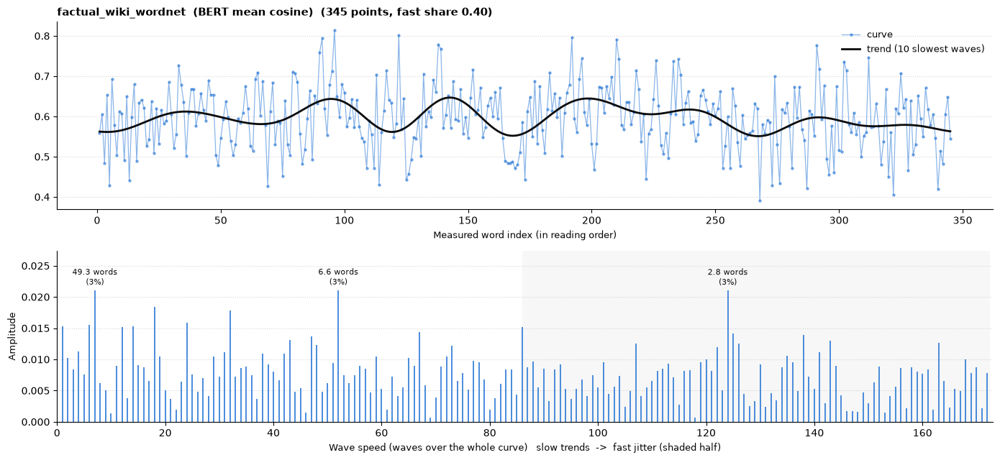

In [7]:
fourier_measurement("BERT mean cosine")

In [8]:
# The 4 measurements side by side: average fast share per kind (1 = all word-to-word jitter, 0 = all slow trend)
rows = []
for measurement, curves in measurements.items():
    shares = {name: fast_share(fourier_transform(curve)) for name, curve in curves.items()}
    factual = [s for n, s in shares.items() if n.startswith("factual")]
    creative = [s for n, s in shares.items() if n.startswith("creative")]
    rows.append({
        "measurement": measurement,
        "factual fast share (mean)": round(sum(factual) / len(factual), 3),
        "creative fast share (mean)": round(sum(creative) / len(creative), 3),
        "difference (creative - factual)": round(sum(creative) / len(creative) - sum(factual) / len(factual), 3),
    })
comparison = pd.DataFrame(rows)
comparison = comparison.reindex(comparison["difference (creative - factual)"].abs()
                                .sort_values(ascending=False).index).reset_index(drop=True)
display(comparison)
print("random jitter (white noise) would give a fast share of about 0.5")

,measurement,factual fast share (mean),creative fast share (mean),difference (creative - factual)
0,BERT mean cosine,0.441,0.471,0.031
1,LCA likely top 3 (10%),0.475,0.456,-0.018
2,Surprisal,0.474,0.485,0.011
3,GloVe top 5,0.483,0.484,0.001


random jitter (white noise) would give a fast share of about 0.5
